# ResNet18 thumbnail classifier

Transfer learning for binary clickbait classification from YouTube thumbnails. Run cells from top to bottom.

**Data boundary:** training rows fit the model; validation rows drive checkpoint selection and metrics. The test CSV is intentionally not loaded until the final cell, for one final evaluation after model choices are fixed.

## 1. Configuration and imports

Run from the repository root or this notebook's `models/` directory. CUDA is used when available. DataLoader workers are deliberately left at PyTorch's Windows-safe default (`num_workers=0`).

In [1]:
from pathlib import Path
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
HEAD_EPOCHS = 3
FINE_TUNE_EPOCHS = 15
PATIENCE = 4
HEAD_LR = 1e-3
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 1e-4
DROPOUT = 0.30
CHECKPOINT_PATH = Path("models/resnet18_best.pt")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Training device: cuda
NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
ROOT = Path.cwd()
if not (ROOT / "data").is_dir() and (ROOT.parent / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"
THUMBNAIL_DIR = ROOT / "Thumbnail"
TRAIN_CSV = DATA_DIR / "train.csv"
VALIDATION_CSV = DATA_DIR / "validation.csv"
TEST_CSV = DATA_DIR / "test.csv"  # Used only in the final evaluation cell.
CHECKPOINT_PATH = ROOT / CHECKPOINT_PATH

for path in (TRAIN_CSV, VALIDATION_CSV):
    if not path.is_file():
        raise FileNotFoundError(f"Required split not found: {path}")

train_df = pd.read_csv(TRAIN_CSV)
validation_df = pd.read_csv(VALIDATION_CSV)

IMAGE_COL = "local_thumbnail"
LABEL_COL = "final_label"
required_columns = {IMAGE_COL, LABEL_COL}
for split_name, frame in (("train", train_df), ("validation", validation_df)):
    missing = required_columns - set(frame.columns)
    if missing:
        raise KeyError(f"{split_name} CSV is missing columns: {sorted(missing)}")
    frame[LABEL_COL] = pd.to_numeric(frame[LABEL_COL], errors="raise").astype(int)
    if not set(frame[LABEL_COL].unique()).issubset({0, 1}):
        raise ValueError(f"{split_name} labels must be binary values 0 and 1")

print(f"Train: {len(train_df):,} rows")
print(f"Validation: {len(validation_df):,} rows")
print("Train label counts:")
display(train_df[LABEL_COL].value_counts().sort_index().rename(index={0: "not clickbait", 1: "clickbait"}))

Train: 2,957 rows
Validation: 634 rows
Train label counts:


final_label
not clickbait    2332
clickbait         625
Name: count, dtype: int64

## 2. Image transforms and dataset

All images are converted to RGB and transformed to the 224×224 input expected by ResNet18. Training uses random resized crop (scale 0.90–1.0) with a wide aspect-ratio range suited to 16:9 thumbnails, limiting edge loss while retaining crop augmentation. Color jitter and random erasing (10% probability; 2–5% area) complete the requested augmentation set. Validation resizes the full frame directly to 224×224 so edge text and graphics remain visible. Normalization uses the ImageNet statistics paired with the pretrained weights.

In [3]:
weights = ResNet18_Weights.IMAGENET1K_V1
image_mean = weights.transforms().mean
image_std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.90, 1.0), ratio=(1.60, 1.90)),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.0,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std),
    transforms.RandomErasing(p=0.10, scale=(0.02, 0.05), value="random"),
])

validation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_mean, std=image_std),
])

class ThumbnailDataset(Dataset):
    """Load RGB thumbnail images and binary labels from a processed split."""

    def __init__(self, frame, root_dir, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.root_dir = Path(root_dir)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def _resolve_image_path(self, value):
        path = Path(str(value))
        if path.is_absolute():
            return path
        candidates = (self.root_dir / path, THUMBNAIL_DIR / path.name)
        for candidate in candidates:
            if candidate.is_file():
                return candidate
        return candidates[0]

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_path = self._resolve_image_path(row[IMAGE_COL])
        if not image_path.is_file():
            raise FileNotFoundError(f"Thumbnail not found: {image_path}")

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            if self.transform is not None:
                image = self.transform(image)

        label = torch.tensor(int(row[LABEL_COL]), dtype=torch.long)
        return image, label

train_dataset = ThumbnailDataset(train_df, ROOT, transform=train_transform)
validation_dataset = ThumbnailDataset(validation_df, ROOT, transform=validation_transform)

# num_workers is intentionally omitted: the default of 0 is reliable on Windows.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=device.type == "cuda")
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=device.type == "cuda")

images, labels = next(iter(train_loader))
print(f"Batch images: {tuple(images.shape)} | labels: {tuple(labels.shape)}")

Batch images: (32, 3, 224, 224) | labels: (32,)


## 3. ResNet18 transfer-learning model

The classifier head is replaced with a dropout-regularized binary output. Training starts with the pretrained feature extractor frozen, then fine-tunes the final residual block and classifier at a lower learning rate. Batch-normalization running statistics in frozen layers remain stable during head warmup.

In [7]:
class ResNet18Classifier(nn.Module):
    """Pretrained ResNet18 with a dropout-regularized binary classifier."""

    def __init__(self, dropout=0.30, weights=ResNet18_Weights.IMAGENET1K_V1):
        super().__init__()
        self.backbone = resnet18(weights=weights)
        input_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(input_features, 1),
        )

    def extract_features(self, images):
        """Return the 512-dimensional pooled visual embedding."""
        backbone = self.backbone
        x = backbone.conv1(images)
        x = backbone.bn1(x)
        x = backbone.relu(x)
        x = backbone.maxpool(x)
        x = backbone.layer1(x)
        x = backbone.layer2(x)
        x = backbone.layer3(x)
        x = backbone.layer4(x)
        x = backbone.avgpool(x)
        return torch.flatten(x, 1)

    def forward(self, images):
        embeddings = self.extract_features(images)
        return self.backbone.fc(embeddings).squeeze(1)

    def freeze_backbone(self):
        for name, parameter in self.backbone.named_parameters():
            parameter.requires_grad = name.startswith("fc.")

    def unfreeze_last_block(self):
        for name, parameter in self.backbone.named_parameters():
            parameter.requires_grad = name.startswith(("layer4.", "fc."))

    def train(self, mode=True):
        super().train(mode)
        # Freeze running statistics for every BatchNorm layer whose parameters are frozen.
        if mode:
            for module in self.backbone.modules():
                if isinstance(module, nn.BatchNorm2d):
                    if not any(parameter.requires_grad for parameter in module.parameters()):
                        module.eval()
        return self

model = ResNet18Classifier(dropout=DROPOUT).to(device)
model.freeze_backbone()
print(f"Trainable parameters during warmup: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Trainable parameters during warmup: 513


## 4. Loss, metrics, and training helpers

The current split is imbalanced, so the positive-class weight is calculated from the training labels only. Validation reports accuracy, precision, recall, F1, and a labeled confusion matrix. The best checkpoint is selected by validation F1; no test data is involved.

In [8]:
class_counts = np.bincount(train_df[LABEL_COL].to_numpy(), minlength=2)
if np.any(class_counts == 0):
    raise ValueError("Training split must contain examples from both classes.")

positive_weight = torch.tensor(
    [class_counts[0] / class_counts[1]],
    dtype=torch.float32,
    device=device,
)
criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

def evaluate(model, loader):
    model.eval()
    all_labels, all_probabilities = [], []
    running_loss, examples = 0.0, 0

    with torch.inference_mode():
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)
            with torch.amp.autocast(device_type=device.type, enabled=device.type == "cuda"):
                logits = model(batch_images)
                loss = criterion(logits, batch_labels.float())

            batch_size = batch_labels.size(0)
            running_loss += loss.item() * batch_size
            examples += batch_size
            all_labels.extend(batch_labels.cpu().numpy().tolist())
            all_probabilities.extend(torch.sigmoid(logits).cpu().numpy().tolist())

    targets = np.asarray(all_labels, dtype=int)
    probabilities = np.asarray(all_probabilities)
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "loss": running_loss / max(examples, 1),
        "accuracy": accuracy_score(targets, predictions),
        "precision": precision_score(targets, predictions, zero_division=0),
        "recall": recall_score(targets, predictions, zero_division=0),
        "f1": f1_score(targets, predictions, zero_division=0),
        "targets": targets,
        "probabilities": probabilities,
        "predictions": predictions,
    }

def train_one_epoch(model, loader, optimizer):
    model.train()
    running_loss, examples = 0.0, 0

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=device.type == "cuda"):
            logits = model(batch_images)
            loss = criterion(logits, batch_labels.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = batch_labels.size(0)
        running_loss += loss.item() * batch_size
        examples += batch_size

    return running_loss / max(examples, 1)

def plot_confusion_matrix(targets, predictions, title="Validation confusion matrix"):
    matrix = confusion_matrix(targets, predictions, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["Not clickbait", "Clickbait"],
        yticklabels=["Not clickbait", "Clickbait"],
        xlabel="Predicted label",
        ylabel="True label",
        title=title,
    )
    for (row, column), value in np.ndenumerate(matrix):
        ax.text(column, row, f"{value:,}", ha="center", va="center")
    fig.colorbar(image, ax=ax, label="Examples")
    fig.tight_layout()
    plt.show()

## 5. Train, fine-tune, and select by validation F1

The first phase warms up the classifier head. The second phase unfreezes ResNet18's final residual block and head for fine-tuning. Early stopping monitors validation F1 and restores the best validation checkpoint.

In [9]:
def fit_phase(model, train_loader, validation_loader, optimizer, epochs, phase_name):
    # Carry the current checkpoint score forward so fine-tuning cannot
    # overwrite a better warmup model with a weaker result.
    initial_metrics = evaluate(model, validation_loader)
    best_f1 = initial_metrics["f1"]
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    history = []

    # Save a valid baseline in case no epoch improves on it.
    CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "model_state_dict": best_state,
            "best_validation_f1": best_f1,
            "phase": f"{phase_name}_baseline",
            "epoch": 0,
            "image_size": IMAGE_SIZE,
            "class_names": {0: "not clickbait", 1: "clickbait"},
        },
        CHECKPOINT_PATH,
    )

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer)
        metrics = evaluate(model, validation_loader)
        history.append({
            "phase": phase_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": metrics["loss"],
            "validation_accuracy": metrics["accuracy"],
            "validation_precision": metrics["precision"],
            "validation_recall": metrics["recall"],
            "validation_f1": metrics["f1"],
        })
        print(
            f"{phase_name} {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f} | val loss {metrics['loss']:.4f} | "
            f"val acc {metrics['accuracy']:.4f} | val F1 {metrics['f1']:.4f} | "
            f"{time.time() - start:.1f}s"
        )

        if metrics["f1"] > best_f1:
            best_f1 = metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
            torch.save(
                {
                    "model_state_dict": best_state,
                    "best_validation_f1": best_f1,
                    "phase": phase_name,
                    "epoch": epoch,
                    "image_size": IMAGE_SIZE,
                    "class_names": {0: "not clickbait", 1: "clickbait"},
                },
                CHECKPOINT_PATH,
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping {phase_name}: validation F1 did not improve for {PATIENCE} epochs.")
            break

    model.load_state_dict(best_state)
    return history

history = []

# Phase 1: train only the new classifier head.
head_optimizer = torch.optim.AdamW(
    (parameter for parameter in model.parameters() if parameter.requires_grad),
    lr=HEAD_LR,
    weight_decay=WEIGHT_DECAY,
)
history.extend(fit_phase(model, train_loader, validation_loader, head_optimizer, HEAD_EPOCHS, "head"))

# Phase 2: fine-tune the last ResNet block and classifier with separate learning rates.
model.unfreeze_last_block()
fine_tune_optimizer = torch.optim.AdamW(
    [
        {"params": model.backbone.layer4.parameters(), "lr": BACKBONE_LR},
        {"params": model.backbone.fc.parameters(), "lr": HEAD_LR / 10},
    ],
    weight_decay=WEIGHT_DECAY,
)
history.extend(fit_phase(model, train_loader, validation_loader, fine_tune_optimizer, FINE_TUNE_EPOCHS, "fine_tune"))

history_df = pd.DataFrame(history)
display(history_df.tail())
print(f"Best validation checkpoint: {CHECKPOINT_PATH}")

head 01/3 | train loss 0.8934 | val loss 0.7086 | val acc 0.8155 | val F1 0.6400 | 110.8s
head 02/3 | train loss 0.7043 | val loss 0.6345 | val acc 0.8044 | val F1 0.6612 | 69.2s
head 03/3 | train loss 0.6603 | val loss 0.5913 | val acc 0.8312 | val F1 0.6767 | 76.9s
fine_tune 01/15 | train loss 0.6302 | val loss 0.4975 | val acc 0.8533 | val F1 0.7224 | 62.2s
fine_tune 02/15 | train loss 0.4811 | val loss 0.4323 | val acc 0.8943 | val F1 0.7832 | 59.3s
fine_tune 03/15 | train loss 0.3905 | val loss 0.4103 | val acc 0.9180 | val F1 0.8182 | 58.6s
fine_tune 04/15 | train loss 0.3408 | val loss 0.3862 | val acc 0.9101 | val F1 0.8055 | 60.8s
fine_tune 05/15 | train loss 0.2978 | val loss 0.3757 | val acc 0.9164 | val F1 0.8153 | 59.0s
fine_tune 06/15 | train loss 0.2580 | val loss 0.3615 | val acc 0.9196 | val F1 0.8235 | 59.0s
fine_tune 07/15 | train loss 0.2125 | val loss 0.3834 | val acc 0.9306 | val F1 0.8394 | 59.4s
fine_tune 08/15 | train loss 0.1819 | val loss 0.3953 | val acc 0.9

,phase,epoch,train_loss,validation_loss,validation_accuracy,validation_precision,validation_recall,validation_f1
10,fine_tune,8,0.181946,0.395275,0.938486,0.851852,0.858209,0.855019
11,fine_tune,9,0.170303,0.380184,0.932177,0.818182,0.873134,0.844765
12,fine_tune,10,0.150101,0.359840,0.932177,0.813793,0.880597,0.845878
13,fine_tune,11,0.124404,0.384889,0.932177,0.822695,0.865672,0.843636
14,fine_tune,12,0.100220,0.397662,0.933754,0.828571,0.865672,0.846715


Best validation checkpoint: d:\DC\multimodal-clickbait-detection\models\resnet18_best.pt


## 6. Review validation performance

These metrics and the confusion matrix are computed on the validation split. Use these results to decide any further parameter changes, then retrain and select the final checkpoint before opening the test split.

Validation accuracy:  0.9385
Validation precision: 0.8519
Validation recall:    0.8582
Validation F1:        0.8550

               precision    recall  f1-score   support

not clickbait       0.96      0.96      0.96       500
    clickbait       0.85      0.86      0.86       134

     accuracy                           0.94       634
    macro avg       0.91      0.91      0.91       634
 weighted avg       0.94      0.94      0.94       634



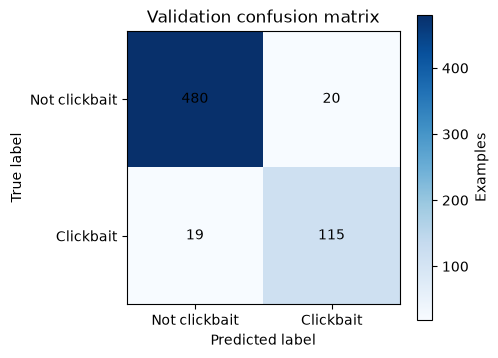

In [10]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
validation_metrics = evaluate(model, validation_loader)

print(f"Validation accuracy:  {validation_metrics['accuracy']:.4f}")
print(f"Validation precision: {validation_metrics['precision']:.4f}")
print(f"Validation recall:    {validation_metrics['recall']:.4f}")
print(f"Validation F1:        {validation_metrics['f1']:.4f}")
print()
print(classification_report(
    validation_metrics["targets"],
    validation_metrics["predictions"],
    labels=[0, 1],
    target_names=["not clickbait", "clickbait"],
    zero_division=0,
))
plot_confusion_matrix(
    validation_metrics["targets"],
    validation_metrics["predictions"],
    title="Validation confusion matrix",
)

## 7. Final test evaluation — run once after model choices are fixed

This cell is the first place that reads `test.csv`. Run it once after completing all tuning using the training and validation splits. Do not use these test results to change hyperparameters.

Final test accuracy:  0.9259
Final test precision: 0.8321
Final test recall:    0.8134
Final test F1:        0.8226

               precision    recall  f1-score   support

not clickbait       0.95      0.96      0.95       500
    clickbait       0.83      0.81      0.82       134

     accuracy                           0.93       634
    macro avg       0.89      0.88      0.89       634
 weighted avg       0.93      0.93      0.93       634



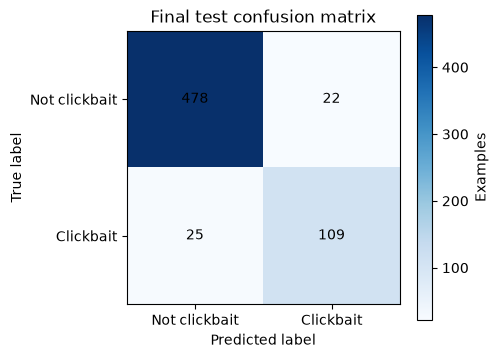

In [11]:
if not TEST_CSV.is_file():
    raise FileNotFoundError(f"Test split not found: {TEST_CSV}")

test_df = pd.read_csv(TEST_CSV)
missing = required_columns - set(test_df.columns)
if missing:
    raise KeyError(f"test CSV is missing columns: {sorted(missing)}")
test_df[LABEL_COL] = pd.to_numeric(test_df[LABEL_COL], errors="raise").astype(int)
if not set(test_df[LABEL_COL].unique()).issubset({0, 1}):
    raise ValueError("test labels must be binary values 0 and 1")

test_dataset = ThumbnailDataset(test_df, ROOT, transform=validation_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=device.type == "cuda")

# Reload the best validation-selected weights before the one-time final evaluation.
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
test_metrics = evaluate(model, test_loader)

print(f"Final test accuracy:  {test_metrics['accuracy']:.4f}")
print(f"Final test precision: {test_metrics['precision']:.4f}")
print(f"Final test recall:    {test_metrics['recall']:.4f}")
print(f"Final test F1:        {test_metrics['f1']:.4f}")
print()
print(classification_report(
    test_metrics["targets"],
    test_metrics["predictions"],
    labels=[0, 1],
    target_names=["not clickbait", "clickbait"],
    zero_division=0,
))
plot_confusion_matrix(
    test_metrics["targets"],
    test_metrics["predictions"],
    title="Final test confusion matrix",
)